In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize
from matplotlib.colors import LinearSegmentedColormap

In [54]:
df_increasing_current = pd.read_csv("increasing_current.csv")
# print(df_increasing_current)

Text(0.5, 1.0, 'B-field/probe insertion distance, increasing current')

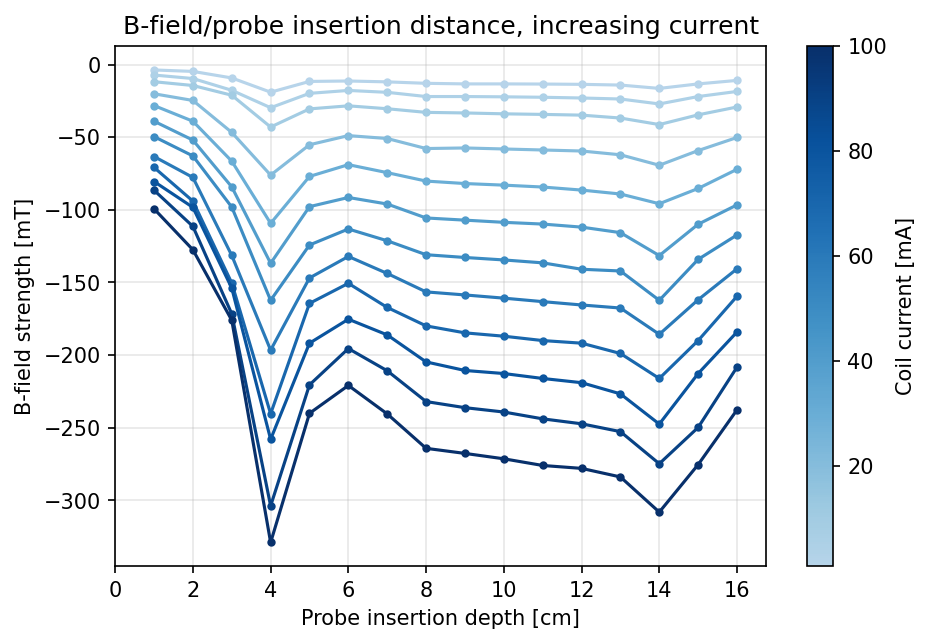

In [58]:
insertion = np.arange(1, 17)
current_values = df_increasing_current.columns.values
currents = np.array([float(str(c).split("_")[0]) for c in current_values])  # '1_mA' -> 1.0

norm = Normalize(currents.min(), currents.max())
base = plt.get_cmap("Blues")
cmap = LinearSegmentedColormap.from_list("Blues_trunc", base(np.linspace(0.3, 1.0, 256)))

fig, ax = plt.subplots(figsize=(7, 4.5), dpi=150)

for c, I in zip(current_values, currents):
    ax.plot(insertion, df_increasing_current[c],
            marker="o", ms=3, lw=1.5, color=cmap(norm(I)))

sm = cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])                      # <- add this
cbar = fig.colorbar(sm, ax=ax)
cbar.set_label("Coil current [mA]")

ax.set_xlabel("Probe insertion depth [cm]")
ax.set_ylabel("B-field strength [mT]")
ax.set_xticks(range(0, 17, 2))
ax.grid(alpha=0.3)
ax.spines[["top",]]
ax.set_title("B-field/probe insertion distance, increasing current")
# ax.colorbar()